# 03 · Hypothesis testing: what do promotions actually change?

Three questions the commercial team asked, each answered with the right test *and* an effect
size — because with 15,000 orders almost everything is "significant", and the real question is
whether the effect is big enough to act on.

| Question | Test | Why this test |
|---|---|---|
| Does free shipping raise order value? | Welch's t-test + bootstrap CI on the median | Two independent groups, unequal variances; order values are right-skewed so a median CI is reported alongside the mean |
| Does promotion type change repeat purchase? | χ² test of independence + Cramér's V | Two categorical variables; V gives the strength of association |
| Do regions differ in order value? | One-way ANOVA (+ Kruskal-Wallis as a robustness check) + pairwise Welch with Bonferroni | Three groups; post-hoc tests tell *which* differ |

**Data:** `data/raw/orders_promotions.csv` (synthetic, seeded). α = 0.05 throughout.

In [2]:
import sys
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from src.stats_utils import welch_ttest, bootstrap_diff_ci, pairwise_welch_bonferroni

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#898781"

orders = pd.read_csv("data/raw/orders_promotions.csv", parse_dates=["order_date"])
orders.groupby("promo_type")["order_value"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
promo_type,,,,,,,,
10_percent_off,2924.0,891548.0,470417.0,135000.0,561000.0,787000.0,1100250.0,5372000.0
free_shipping,3879.0,1046712.0,524792.0,195000.0,678000.0,935000.0,1296500.0,5865000.0
none,8197.0,934522.0,469952.0,131000.0,604000.0,837000.0,1157000.0,4441000.0


## Q1 · Does free shipping lift order value?

* H₀: mean order value is the same with and without free shipping.
* H₁: it differs (two-sided — we do not assume the direction).

Order values are right-skewed (mean ≫ median), so I check the distribution first; the t-test
is robust at these sample sizes but I report a bootstrap CI on the **median** as well, which is
the number a merchandiser would recognise.

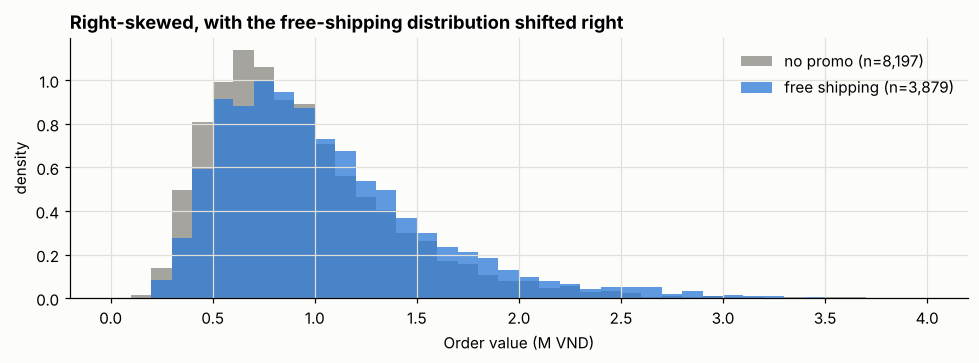

In [4]:
fs = orders.loc[orders["promo_type"] == "free_shipping", "order_value"]
none = orders.loc[orders["promo_type"] == "none", "order_value"]

fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.arange(0, 4_000_001, 100_000)
ax.hist(none / 1e6, bins=bins / 1e6, alpha=0.75, color=MUTED, label=f"no promo (n={len(none):,})", density=True)
ax.hist(fs / 1e6, bins=bins / 1e6, alpha=0.75, color=BLUE, label=f"free shipping (n={len(fs):,})", density=True)
ax.set_xlabel("Order value (M VND)"); ax.set_ylabel("density"); ax.legend(frameon=False)
ax.set_title("Right-skewed, with the free-shipping distribution shifted right")
plt.tight_layout()

In [5]:
res = welch_ttest(fs, none)
med_lo, med_hi = bootstrap_diff_ci(fs, none, stat=np.median, n_boot=4000, seed=3)
print(f"Mean order value:   free shipping {res['mean_a']:,.0f}  vs  none {res['mean_b']:,.0f}  VND")
print(f"Difference in means: {res['diff']:+,.0f} VND, 95% CI [{res['ci_low']:+,.0f}, {res['ci_high']:+,.0f}]")
print(f"Welch t = {res['t']:.2f}, df ≈ {res['df']:.0f}, p = {res['p_value']:.2e}")
print(f"Cohen's d = {res['cohens_d']:.2f}  (small-to-medium effect)")
print(f"Difference in medians: {fs.median() - none.median():+,.0f} VND, bootstrap 95% CI [{med_lo:+,.0f}, {med_hi:+,.0f}]")
print(f"Items per order: free shipping {orders.loc[orders.promo_type == 'free_shipping', 'items'].mean():.2f}  vs  none {orders.loc[orders.promo_type == 'none', 'items'].mean():.2f}")

Mean order value:   free shipping 1,046,712  vs  none 934,522  VND
Difference in means: +112,190 VND, 95% CI [+92,790, +131,591]
Welch t = 11.34, df ≈ 6909, p = 1.58e-29
Cohen's d = 0.23  (small-to-medium effect)
Difference in medians: +98,000 VND, bootstrap 95% CI [+75,000, +120,000]
Items per order: free shipping 2.99  vs  none 2.70


**Reject H₀.** Orders with free shipping are **~112k VND (+12%) larger on average**, CI roughly
+93k to +132k; the median moves by a similar amount (+75k to +119k). Items per order rises
from 2.7 to 3.0 — people add an item to reach the threshold, which is exactly the behaviour the
promotion is designed to produce.

**Is it worth it?** Shipping costs ~25k VND per order. A ~112k uplift in order value at a ~55%
gross margin is ~60k of extra margin per order — the promotion pays for itself more than twice
over *before* any repeat-purchase effect. Caveat: this is observational data, not an experiment;
customers who choose free-shipping offers may already be bigger spenders. The A/B framework in
notebook 02 is how I would confirm the causal claim.

## Q2 · Does promotion type affect repeat purchase within 90 days?

* H₀: repeat purchase is independent of promotion type.

In [8]:
ct = pd.crosstab(orders["promo_type"], orders["repeat_within_90d"], margins=True)
ct.columns = ["no repeat", "repeat", "total"]
ct["repeat_rate_%"] = 100 * ct["repeat"] / ct["total"]
ct.round(1)

,no repeat,repeat,total,repeat_rate_%
promo_type,,,,
10_percent_off,2038,886,2924,30.3
free_shipping,2480,1399,3879,36.1
none,5595,2602,8197,31.7
All,10113,4887,15000,32.6


In [9]:
chi2, p, dof, expected = stats.chi2_contingency(pd.crosstab(orders["promo_type"], orders["repeat_within_90d"]))
cramers_v = np.sqrt(chi2 / len(orders))
print(f"χ² = {chi2:.2f}, dof = {dof}, p = {p:.2e}  ->  reject independence")
print(f"Cramér's V = {cramers_v:.3f}  ->  but the association is WEAK (V < 0.1)")

χ² = 30.99, dof = 2, p = 1.87e-07  ->  reject independence
Cramér's V = 0.045  ->  but the association is WEAK (V < 0.1)


**Statistically significant, practically small.** Free-shipping orders repeat at 36% vs 32% for
no-promo and 30% for 10%-off. With n = 15,000 the χ² test rejects easily, but Cramér's V = 0.045
says promotion type explains very little of who comes back. For comparison, the *channel* the
order came from has V ≈ 0.12 — nearly three times the association:

In [11]:
ct_ch = pd.crosstab(orders["channel"], orders["repeat_within_90d"])
chi2_ch, p_ch, _, _ = stats.chi2_contingency(ct_ch)
pd.DataFrame({
    "repeat_rate_%": (100 * ct_ch[1] / ct_ch.sum(axis=1)).round(1),
    "orders": ct_ch.sum(axis=1),
}).assign(**{"Cramér's V (channel)": round(np.sqrt(chi2_ch / len(orders)), 3)})

,repeat_rate_%,orders,Cramér's V (channel)
channel,,,
marketplace,24.9,3742,0.117
mobile_app,39.0,5527,0.117
web,31.4,5731,0.117


If the goal is retention, the lever is getting customers onto the **mobile app** (39% repeat vs
25% on marketplace), not the promotion mechanic. The 4-point free-shipping effect is real but
second-order.

## Q3 · Do regions differ in order value?

* H₀: mean order value is equal across North, Central and South.

ANOVA assumes roughly equal variances; Levene's test checks that, and Kruskal-Wallis (rank-based)
is run as a robustness check because of the skew. If H₀ is rejected, pairwise Welch tests with a
Bonferroni correction say *which* regions differ.

In [14]:
groups = {r: g["order_value"] for r, g in orders.groupby("region")}
lev = stats.levene(*groups.values())
f = stats.f_oneway(*groups.values())
kw = stats.kruskal(*groups.values())
print(f"Levene's test for equal variances: W = {lev.statistic:.2f}, p = {lev.pvalue:.1e}  -> variances differ (use Welch post-hoc)")
print(f"One-way ANOVA:  F = {f.statistic:.2f}, p = {f.pvalue:.1e}  -> reject equal means")
print(f"Kruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.1e}  -> same conclusion on ranks")
orders.groupby("region")["order_value"].agg(["count", "mean", "median", "std"]).round(0)

Levene's test for equal variances: W = 11.96, p = 6.5e-06  -> variances differ (use Welch post-hoc)
One-way ANOVA:  F = 45.73, p = 1.6e-20  -> reject equal means
Kruskal-Wallis: H = 102.02, p = 7.0e-23  -> same conclusion on ranks


,count,mean,median,std
region,,,,
Central,2700,889842.0,790500.0,455852.0
North,6236,944964.0,846000.0,478795.0
South,6064,994722.0,889500.0,507404.0


In [15]:
posthoc = pairwise_welch_bonferroni(orders, "region", "order_value")
posthoc.round(6)

,group_1,group_2,diff,p_raw,p_bonferroni,significant_5pct
0,Central,North,-55121.746609,0.0,0.000001,True
1,Central,South,-104880.443663,0.0,0.000000,True
2,North,South,-49758.697054,0.0,0.000000,True


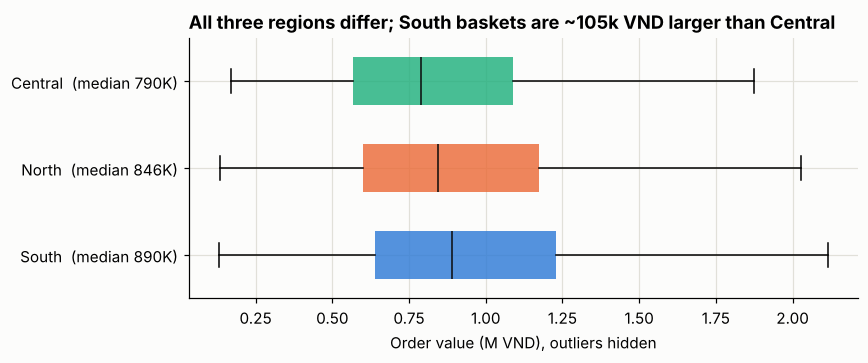

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.4))
order = ["South", "North", "Central"]
data = [orders.loc[orders.region == r, "order_value"] / 1e6 for r in order]
bp = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=0.55)
for patch, c in zip(bp["boxes"], [BLUE, ORANGE, AQUA]):
    patch.set_facecolor(c); patch.set_alpha(0.8); patch.set_edgecolor("none")
for med in bp["medians"]:
    med.set_color("#0b0b0b")
ax.set_yticklabels([f"{r}  (median {orders.loc[orders.region == r, 'order_value'].median() / 1e3:,.0f}K)" for r in order])
ax.set_xlabel("Order value (M VND), outliers hidden")
ax.set_title("All three regions differ; South baskets are ~105k VND larger than Central")
plt.tight_layout()

**Reject H₀; all three pairwise differences survive Bonferroni.** South orders average ~995k,
North ~945k, Central ~890k VND. The South–Central gap (~105k, ~11%) is large enough to matter for
regional free-shipping thresholds: a single national threshold is effectively a steeper ask in
Central.

## Bonus · Delivery time and satisfaction (a correlation, not a test)

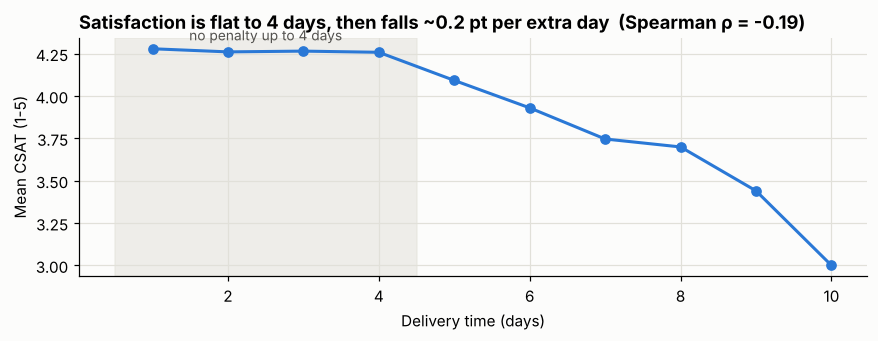

In [19]:
rho = stats.spearmanr(orders["delivery_days"], orders["csat_score"])
by_day = orders.groupby("delivery_days")["csat_score"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(by_day.index, by_day["mean"], marker="o", color=BLUE, lw=2)
ax.axvspan(0.5, 4.5, color="#e1e0d9", alpha=0.5)
ax.text(2.5, by_day["mean"].max() + 0.05, "no penalty up to 4 days", ha="center", fontsize=9, color="#52514e")
ax.set_xlabel("Delivery time (days)"); ax.set_ylabel("Mean CSAT (1-5)")
ax.set_title(f"Satisfaction is flat to 4 days, then falls ~0.2 pt per extra day  (Spearman ρ = {rho.statistic:.2f})")
plt.tight_layout()

Satisfaction is unaffected up to a 4-day delivery and then drops roughly 0.2 points per day. The
practical reading: a 4-day promise is safe; a 5-day promise is where complaints start. (Central's
longer delivery times are a plausible contributor to its lower basket, but that is a hypothesis,
not something this data can establish.)

## Summary for the commercial team

| Question | Answer | Effect size | Action |
|---|---|---|---|
| Free shipping → order value? | Yes, +12% (+112k VND) | d = 0.23 | Keep; it pays for itself ~2× on margin. Confirm causally with an A/B. |
| Promo type → repeat purchase? | Yes, but weakly | V = 0.045 | Don't use promos as a retention tool; channel (app) matters 3× more. |
| Regions differ in order value? | Yes, all pairs | South ≈ Central + 11% | Consider region-specific free-shipping thresholds. |
| Delivery time → CSAT? | Flat to 4 days, then falls | ρ = −0.19 | Hold the 4-day promise; prioritise Central logistics. |

Every "yes" above comes with its effect size because p-values at n = 15,000 are not the
decision criterion — the size of the effect against the cost of acting is.